# 01 - Exploración inicial

**Proyecto:** Estacionalidad y composición del delito en la Región de Valparaíso (EIN092B, 2026-2)

**Pregunta:** ¿Qué familias y tipos de delito predominan en la Región de Valparaíso y cómo evoluciona su frecuencia mes a mes y año a año (2019-2025)?

- **X:** familia de delito, tipo de delito, mes, año
- **Y:** casos policiales (y derivados: participación %, índice estacional)
- **T:** 2019-2026, mensual (2026 hasta junio)

**Fuente:** CEAD, Casos Policiales, Región de Valparaíso.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
MESES = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']

## 1. Cargar datos

Antes: `python src/data_prep.py` genera los CSV tidy desde el export del CEAD.

In [2]:
mensual = pd.read_csv('../data/processed/delitos_valparaiso_mensual.csv')
anual = pd.read_csv('../data/processed/delitos_valparaiso_anual.csv')
mensual['fecha'] = pd.to_datetime(dict(year=mensual['anio'], month=mensual['mes'], day=1))
fam_m = mensual[mensual['nivel'] == 'familia'].copy()
fam_a = anual[anual['nivel'] == 'familia'].copy()
sub_a = anual[anual['nivel'] == 'subtipo'].copy()
print('mensual:', mensual.shape, '| anual:', anual.shape)
mensual.head()

mensual: (2520, 7) | anual: (224, 5)


,anio,mes,familia,delito,nivel,casos,fecha
0,2019,1,Delitos contra la vida o integridad de las per...,Delitos contra la vida o integridad de las per...,familia,2299,2019-01-01
1,2019,2,Delitos contra la vida o integridad de las per...,Delitos contra la vida o integridad de las per...,familia,1983,2019-02-01
2,2019,3,Delitos contra la vida o integridad de las per...,Delitos contra la vida o integridad de las per...,familia,2208,2019-03-01
3,2019,4,Delitos contra la vida o integridad de las per...,Delitos contra la vida o integridad de las per...,familia,2107,2019-04-01
4,2019,5,Delitos contra la vida o integridad de las per...,Delitos contra la vida o integridad de las per...,familia,2103,2019-05-01


## 2. Composición del delito 

¿Qué familias pesan más? Año 2025 (último completo).

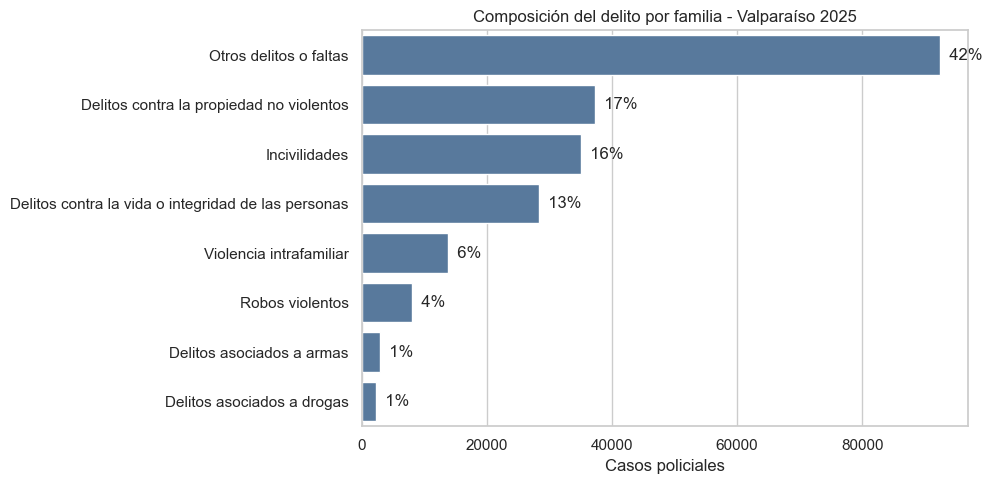

In [3]:
comp = fam_a[fam_a['anio'] == 2025].sort_values('casos', ascending=False)
comp['pct'] = 100 * comp['casos'] / comp['casos'].sum()
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=comp, y='familia', x='casos', color='#4C78A8')
ax.set_title('Composición del delito por familia - Valparaíso 2025')
ax.set_xlabel('Casos policiales'); ax.set_ylabel('')
for i, r in enumerate(comp.itertuples()):
    ax.text(r.casos, i, f'  {r.pct:.0f}%', va='center')
plt.tight_layout(); plt.show()

## 3. Tendencia interanual 

2019-2025 por familia (hover para valores; se excluye 2026 incompleto).

In [4]:
serie = fam_a[fam_a['anio'] <= 2025]
figp = px.line(serie, x='anio', y='casos', color='familia', markers=True,
               title='Evolución de las familias de delito - Valparaíso (2019-2025)')
figp.update_layout(xaxis_title='Año', yaxis_title='Casos policiales', legend_title='Familia')
figp.show()

## 4. Serie mensual continua 

Toda la historia mes a mes: se ven a la vez la tendencia y la estacionalidad.

In [5]:
figm = px.line(fam_m, x='fecha', y='casos', color='familia',
               title='Casos mensuales por familia - Valparaíso (2019-2026)')
figm.update_layout(xaxis_title='Mes', yaxis_title='Casos policiales', legend_title='Familia')
figm.show()

## 5. Estacionalidad: heatmap mes x año 

Elegimos una familia para ver el patrón estacional (filas = mes, columnas = año).

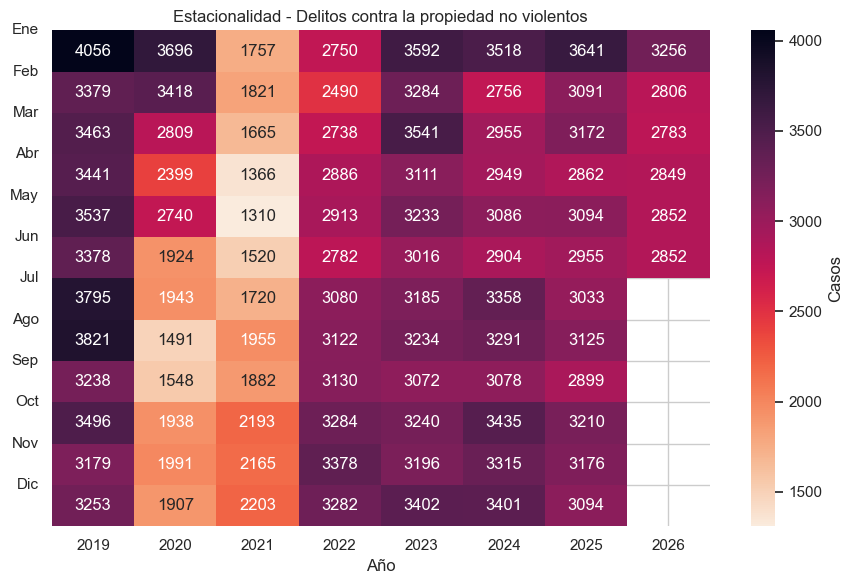

In [6]:
familia = 'Delitos contra la propiedad no violentos'
d = fam_m[fam_m['familia'] == familia]
piv = d.pivot_table(index='mes', columns='anio', values='casos')
plt.figure(figsize=(9, 6))
sns.heatmap(piv, annot=True, fmt='.0f', cmap='rocket_r', cbar_kws={'label': 'Casos'})
plt.title(f'Estacionalidad - {familia}')
plt.yticks(range(12), MESES, rotation=0); plt.xlabel('Año'); plt.ylabel('')
plt.tight_layout(); plt.show()

## 6. Índice estacional 

Promedio de cada mes calendario relativo al promedio general (100 = mes típico), 2019-2025.

/var/folders/qh/p_5g9hgd0c3465m6nvx0cg0c0000gn/T/ipykernel_13145/2176243054.py:6: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/var/folders/qh/p_5g9hgd0c3465m6nvx0cg0c0000gn/T/ipykernel_13145/2176243054.py:8: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



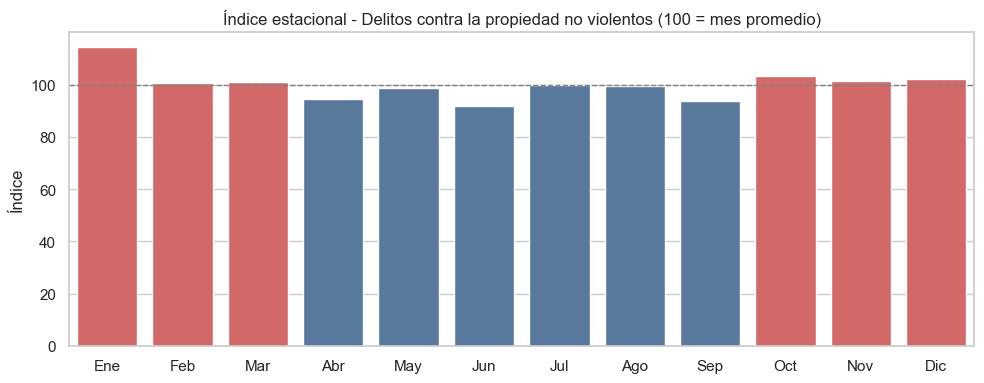

In [7]:
base = fam_m[(fam_m['familia'] == familia) & (fam_m['anio'] <= 2025)]
prom_mes = base.groupby('mes')['casos'].mean()
indice = 100 * prom_mes / prom_mes.mean()
plt.figure(figsize=(10, 4))
colores = ['#E45756' if v >= 100 else '#4C78A8' for v in indice]
ax = sns.barplot(x=list(range(1, 13)), y=indice.values, palette=colores)
ax.axhline(100, color='gray', ls='--', lw=1)
ax.set_xticklabels(MESES)
ax.set_title(f'Índice estacional - {familia} (100 = mes promedio)')
ax.set_xlabel(''); ax.set_ylabel('Índice')
plt.tight_layout(); plt.show()

## 7. subtipos de una familia

In [8]:
ds = sub_a[(sub_a['familia'] == familia) & (sub_a['anio'] == 2025)].sort_values('casos')
figb = px.bar(ds, x='casos', y='delito', orientation='h',
              title=f'Subtipos - {familia} (2025)')
figb.update_layout(xaxis_title='Casos policiales', yaxis_title='')
figb.show()